In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from sktime.transformations.series.outlier_detection import HampelFilter
from sktime.transformations.series.impute import Imputer
from plotly.subplots import make_subplots

df = pd.read_csv(r'C:\Users\user\Desktop\ДАННЫЕ ПО MOEX\SPREADS\SILV-12.26-3.27 [Price].csv')
df['<DATE>'] = pd.to_datetime(df['<DATE>'], format="%Y%m%d")
df["DATETIME"] = pd.to_datetime(
    df["<DATE>"].astype(str) + " " +
    df["<TIME>"].astype(str).str.zfill(6),
    format="%Y-%m-%d %H%M%S")
df.insert(2, "DATETIME", df.pop('DATETIME'))
del df['<DATE>'], df['<TIME>']
df.rename(columns={'<TICKER>':'TICKER','<OPEN>': 'OPEN','<HIGH>' : 'HIGH', '<LOW>' : 'LOW' ,'<CLOSE>': 'CLOSE'}, inplace=True)
data1 = go.Ohlc(close=df['CLOSE'], high=df['HIGH'], low=df['LOW'], open=df['OPEN'], x=df['DATETIME'])
chart_title = str(df['TICKER'].iloc[1]) +' ' + str(df['<PER>'].iloc[1])
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.03, row_heights=[0.7, 0.3],)
fig.add_trace(data1, row=1, col=1)
fig.add_trace(go.Bar(x=df['DATETIME'], y=df['<VOL>'], name='Volume', marker_color='#00D2FF', opacity=1.0), row=2, col=1)
fig.update_xaxes(rangeslider_visible=False, rangebreaks=[dict(bounds=["sat", "mon"])])
fig.update_layout(title=chart_title)
fig

In [2]:
time_from = input('enter time in format YYYY-MM-DD HH:MM:SS')
df = df[df['DATETIME'] > time_from].reset_index(drop=True)
df = df.drop(columns=['OPEN', 'HIGH', 'LOW', '<VOL>', '<PER>'], errors='ignore')
df.isna().sum()

TICKER      0
DATETIME    0
CLOSE       0
dtype: int64

In [3]:
df['CLOSE'].info()
df['CLOSE'].describe()

<class 'pandas.Series'>
RangeIndex: 757 entries, 0 to 756
Series name: CLOSE
Non-Null Count  Dtype  
--------------  -----  
757 non-null    float64
dtypes: float64(1)
memory usage: 6.0 KB


count    757.000000
mean       1.588468
std        0.134448
min        1.280000
25%        1.510000
50%        1.580000
75%        1.640000
max        1.940000
Name: CLOSE, dtype: float64

In [4]:
hampel_window = int(input('enter hampel window size'))
hampel_sigma = int(input('enter hampel sigma'))
hampel_cleaned = (HampelFilter(window_length=hampel_window, n_sigma=hampel_sigma) * Imputer(method="nearest", random_state=42)).fit_transform(df['CLOSE'])
df['h-cleaned'] = hampel_cleaned
hampel_nan_res = df['h-cleaned'].isna().sum()
print(f'''Nan results in hampel cleared series: {hampel_nan_res} \nhampel parameter window: {hampel_window} sigma: {hampel_sigma}''')

Nan results in hampel cleared series: 0 
hampel parameter window: 41 sigma: 3


<Axes: >

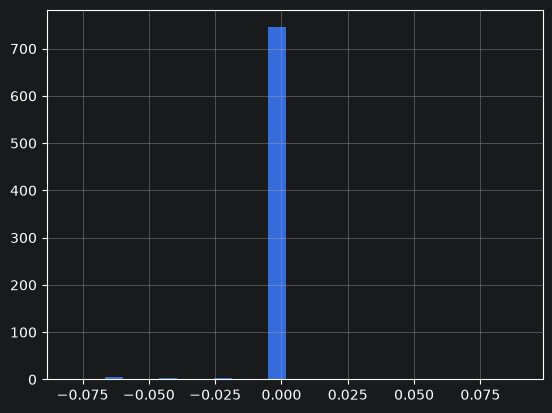

In [5]:
df['residual'] = df['CLOSE'] - df['h-cleaned']
df['residual'].hist(bins=25)

(array([1., 0., 4., 0., 1., 2., 0., 1., 2., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 1.]),
 array([-0.08  , -0.0732, -0.0664, -0.0596, -0.0528, -0.046 , -0.0392,
        -0.0324, -0.0256, -0.0188, -0.012 , -0.0052,  0.0016,  0.0084,
         0.0152,  0.022 ,  0.0288,  0.0356,  0.0424,  0.0492,  0.056 ,
         0.0628,  0.0696,  0.0764,  0.0832,  0.09  ]),
 <BarContainer object of 25 artists>)

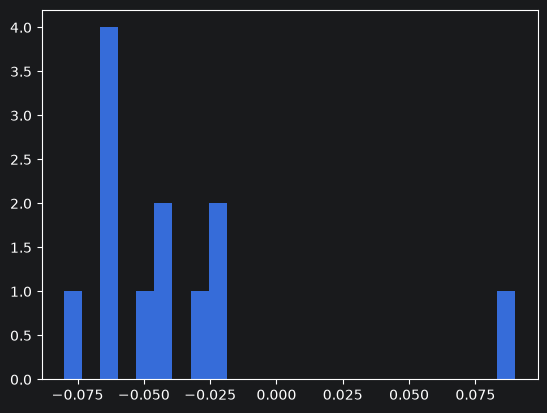

In [6]:
plt.hist(df['residual'][df['residual']!=0], bins=25)

In [7]:
data_cleaned = go.Scatter(x=df['DATETIME'], y=df['h-cleaned'])
layout_cleaned = go.Layout(title=chart_title + ' cleaned')
fig = go.Figure(data=data_cleaned, layout=layout_cleaned)
fig.update_xaxes(rangebreaks=[dict(bounds=["sat", "mon"])])
fig

In [8]:
data_origin = go.Scatter(x=df['DATETIME'], y=df['CLOSE'])
layout_origin = go.Layout(title=chart_title + ' original')
fig = go.Figure(data=data_origin, layout=layout_origin)
fig.update_xaxes(rangebreaks=[dict(bounds=["sat", "mon"])])
fig

In [10]:
df = df.drop(columns='residual', errors='ignore')
df
%store df

Stored 'df' (DataFrame)
